# Experiment 6: GloVe Word Embeddings

**Aim:** Implement the GloVe (Global Vectors for Word Representation) algorithm to generate word embeddings from a text corpus and find the most similar words to **"king"**.

| Part | Approach |
|------|----------|
| 1 | GloVe implemented from scratch (no pretrained model) |
| 2 | Pretrained GloVe vectors loaded using Gensim |

## Part 1: GloVe from Scratch

### Step 1: Import Libraries

In [17]:
import re
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt

np.random.seed(42)

### Step 2: Load and Preprocess the Corpus
Lowercase the text, remove punctuation and split each line into tokens.

In [18]:
with open("glove_corpus.txt", "r") as f:
    lines = f.read().splitlines()

sentences = [re.findall(r"[a-z]+", line.lower()) for line in lines if line.strip()]

print("Number of sentences:", len(sentences))
print("Sample sentence    :", sentences[0])

Number of sentences: 24
Sample sentence    : ['the', 'king', 'rules', 'the', 'kingdom']


### Step 4: Build the Vocabulary

In [19]:
vocab = sorted({word for sent in sentences for word in sent})
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
V = len(vocab)

print("Vocabulary size:", V)
print(vocab)

Vocabulary size: 68
['a', 'and', 'around', 'at', 'books', 'brave', 'cat', 'computer', 'conducts', 'data', 'daughter', 'develops', 'doctor', 'dog', 'drinks', 'earth', 'eats', 'food', 'gives', 'heat', 'house', 'in', 'information', 'intelligent', 'is', 'kind', 'king', 'kingdom', 'laboratory', 'learn', 'light', 'live', 'lives', 'man', 'milk', 'moon', 'new', 'night', 'of', 'palace', 'patient', 'powerful', 'prince', 'princess', 'processes', 'queen', 'read', 'research', 'revolves', 'royal', 'rule', 'rules', 'school', 'scientist', 'shines', 'software', 'son', 'strong', 'students', 'sun', 'teacher', 'teaches', 'the', 'things', 'together', 'treats', 'wise', 'woman']


### Step 5: Build the Co-occurrence Matrix
For every word, count the context words within a window. Closer words contribute more (weight = 1 / distance), as in the original GloVe paper.

In [20]:
WINDOW_SIZE = 4

cooc = defaultdict(float)

for sent in sentences:
    for i, word in enumerate(sent):
        for j in range(max(0, i - WINDOW_SIZE), min(len(sent), i + WINDOW_SIZE + 1)):
            if i != j:
                distance = abs(i - j)
                cooc[(word2idx[word], word2idx[sent[j]])] += 1.0 / distance

print("Non-zero co-occurrence pairs:", len(cooc))

Non-zero co-occurrence pairs: 496


### Step 6: Initialise GloVe Parameters
Each word gets a word vector `W`, a context vector `W_tilde` and two bias terms. AdaGrad accumulators are also created for stable training.

In [21]:
EMBED_DIM = 20
X_MAX = 10
ALPHA = 0.75
LEARNING_RATE = 0.05
EPOCHS = 300

W       = (np.random.rand(V, EMBED_DIM) - 0.5) / EMBED_DIM
W_tilde = (np.random.rand(V, EMBED_DIM) - 0.5) / EMBED_DIM
b       = np.zeros(V)
b_tilde = np.zeros(V)

# AdaGrad accumulators
gW       = np.ones((V, EMBED_DIM))
gW_tilde = np.ones((V, EMBED_DIM))
gb       = np.ones(V)
gb_tilde = np.ones(V)

training_data = [(i, j, x) for (i, j), x in cooc.items()]

### Step 7: Define the GloVe Weighting Function and Training Loop
Loss for each pair: `f(X_ij) * (w_i . w~_j + b_i + b~_j - log X_ij)^2`
where `f(x) = (x / x_max)^alpha` if `x < x_max`, else `1`.

In [22]:
def weight_fn(x):
    return (x / X_MAX) ** ALPHA if x < X_MAX else 1.0


def train_glove():
    loss_history = []
    for epoch in range(EPOCHS):
        np.random.shuffle(training_data)
        total_loss = 0.0

        for i, j, x in training_data:
            f = weight_fn(x)
            diff = W[i] @ W_tilde[j] + b[i] + b_tilde[j] - np.log(x)
            total_loss += 0.5 * f * diff ** 2

            grad = f * diff
            grad_W       = grad * W_tilde[j]
            grad_W_tilde = grad * W[i]

            # AdaGrad updates
            W[i]       -= LEARNING_RATE * grad_W / np.sqrt(gW[i])
            W_tilde[j] -= LEARNING_RATE * grad_W_tilde / np.sqrt(gW_tilde[j])
            b[i]       -= LEARNING_RATE * grad / np.sqrt(gb[i])
            b_tilde[j] -= LEARNING_RATE * grad / np.sqrt(gb_tilde[j])

            gW[i]       += grad_W ** 2
            gW_tilde[j] += grad_W_tilde ** 2
            gb[i]       += grad ** 2
            gb_tilde[j] += grad ** 2

        loss_history.append(total_loss)
        if (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch + 1:3d}/{EPOCHS} | Loss: {total_loss:.4f}")
    return loss_history

### Step 8: Train the Model

In [23]:
loss_history = train_glove()

Epoch  50/300 | Loss: 10.0157
Epoch 100/300 | Loss: 4.6798
Epoch 150/300 | Loss: 2.9415
Epoch 200/300 | Loss: 1.9990
Epoch 250/300 | Loss: 1.3342
Epoch 300/300 | Loss: 0.8301


### Step 9: Plot the Training Loss

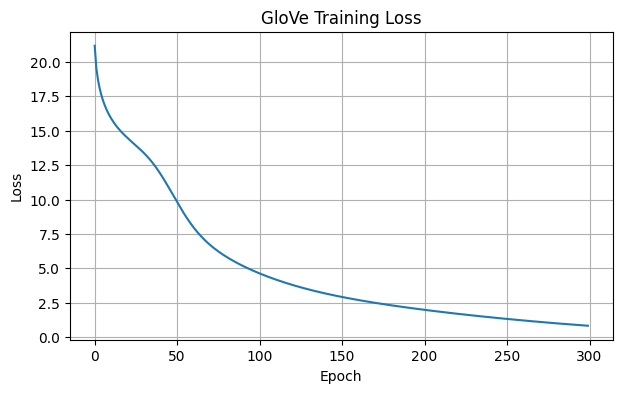

In [24]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GloVe Training Loss")
plt.grid(True)
plt.show()

### Step 10: Final Embeddings
The final embedding of a word is the sum of its word vector and context vector, as recommended in the GloVe paper.

In [25]:
embeddings = W + W_tilde
print("Embedding matrix shape:", embeddings.shape)
print("Vector for 'king':\n", np.round(embeddings[word2idx["king"]], 3))

Embedding matrix shape: (68, 20)
Vector for 'king':
 [ 0.348 -0.007  0.565  0.652 -0.189  0.146 -0.639 -0.519  0.281  0.077
  0.313 -0.505  0.051 -0.168  0.2    0.197 -0.075 -0.376 -0.092 -0.313]


### Step 11: Find the Most Similar Words (Cosine Similarity)

In [26]:
def most_similar(word, top_n=5):
    if word not in word2idx:
        raise KeyError(f"'{word}' is not in the vocabulary")

    vec = embeddings[word2idx[word]]
    norms = np.linalg.norm(embeddings, axis=1) * np.linalg.norm(vec)
    sims = (embeddings @ vec) / (norms + 1e-10)

    ranked = np.argsort(-sims)
    return [(idx2word[i], float(sims[i])) for i in ranked if idx2word[i] != word][:top_n]


print("Most similar words to 'king' (from scratch):\n")
for w, s in most_similar("king", top_n=5):
    print(f"{w:<12} {s:.4f}")

Most similar words to 'king' (from scratch):

the          0.9064
queen        0.8347
rules        0.8210
is           0.6782
princess     0.6444


### Step 12: Visualise the Embeddings in 2D (PCA)

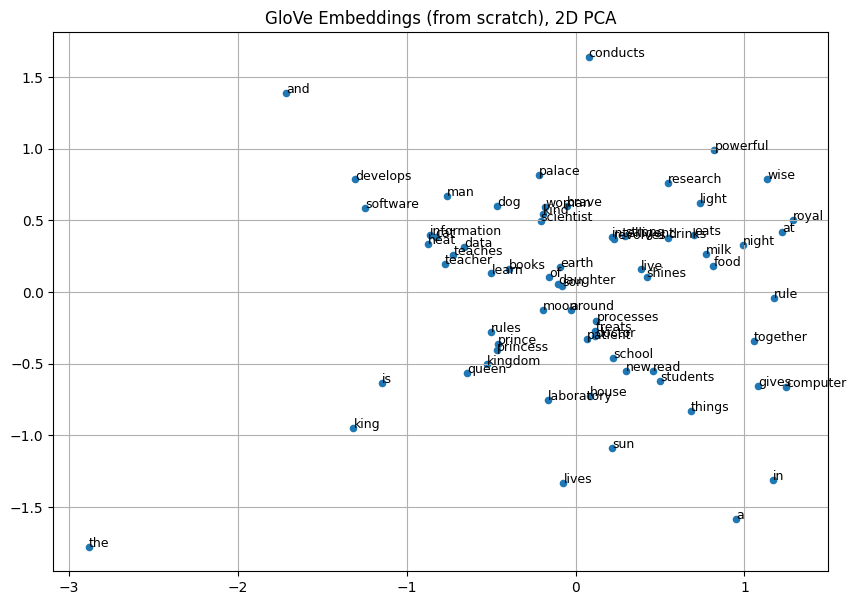

In [11]:
centered = embeddings - embeddings.mean(axis=0)
_, _, Vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ Vt[:2].T

plt.figure(figsize=(10, 7))
plt.scatter(coords[:, 0], coords[:, 1], s=20)
for i, word in idx2word.items():
    plt.annotate(word, (coords[i, 0], coords[i, 1]), fontsize=9)
plt.title("GloVe Embeddings (from scratch), 2D PCA")
plt.grid(True)
plt.show()

---
## Part 2: Pretrained GloVe using Gensim

### Step 1: Install and Import Gensim

In [12]:
!pip install -q gensim

In [13]:
import gensim.downloader as api

### Step 2: Load the Pretrained GloVe Model
`glove-wiki-gigaword-50` contains 50-dimensional vectors trained on Wikipedia and Gigaword (400k words). An internet connection is required for the first download.

In [14]:
glove_model = api.load("glove-wiki-gigaword-50")

print("Vocabulary size :", len(glove_model.key_to_index))
print("Vector dimension:", glove_model.vector_size)

[==================================================] 100.0% 66.0/66.0MB downloaded
Vocabulary size : 400000
Vector dimension: 50


### Step 3: Find the Most Similar Words to "king"

In [15]:
print("Most similar words to 'king' (pretrained GloVe):\n")
for word, score in glove_model.most_similar("king", topn=5):
    print(f"{word:<12} {score:.4f}")

Most similar words to 'king' (pretrained GloVe):

prince       0.8236
queen        0.7839
ii           0.7746
emperor      0.7736
son          0.7667


### Step 4: Extra Checks (Similarity and Analogy)

In [16]:
print("Similarity(king, queen):", round(float(glove_model.similarity("king", "queen")), 4))
print("Similarity(king, cat)  :", round(float(glove_model.similarity("king", "cat")), 4))

print("\nAnalogy: king - man + woman = ?")
for word, score in glove_model.most_similar(positive=["king", "woman"], negative=["man"], topn=3):
    print(f"{word:<12} {score:.4f}")

Similarity(king, queen): 0.7839
Similarity(king, cat)  : 0.3863

Analogy: king - man + woman = ?
queen        0.8524
throne       0.7664
prince       0.7592


---
## Conclusion
- GloVe learns word vectors by factorising the **log co-occurrence matrix** of a corpus.
- On the tiny corpus (Part 1), words that share contexts with "king" (such as "queen", "man", "kingdom") come out as similar. Results are limited by the small corpus size.
- The pretrained model (Part 2) is trained on billions of tokens, so its neighbours of "king" are far more meaningful and it can solve analogies such as king - man + woman = queen.